# 02 — Classical Machine Learning (scikit-learn)
**CodeCraft · Early Metabolic Risk Detection · NHANES 2017–2018**

> ⚠️ **Research/educational use only. Not a diagnosis or medical advice.**
> The data are **cross-sectional**: results describe classification *within this survey cycle*, **not** prediction of future disease.
> All metrics are **unweighted** (survey weights are not available). No claim is made about which model family (classical ML, deep learning, quantum ML) is better; only real runs from this notebook are reported.

**Task:** binary classification, positive class = *Elevated Risk* (HbA1c 5.7 % to < 6.5 %, label 1) vs *Normal* (< 5.7 %, label 0).

## How to run
- **Needed in Drive** (`MyDrive/CodeCraft/`): `train.csv`, `validation.csv`, `test.csv`, `split_manifest.json`.
- **Run order across notebooks:** `02_ml_model` → `03` → `04` → `05`. **This notebook creates** `results/shared_feature_set.json`, which 03–05 load.
- Use *Runtime → Run all* on a fresh Colab runtime (CPU is enough). Expected runtime: about 3–10 minutes (grid searches dominate).
- Everything written goes under `MyDrive/CodeCraft/results/` (survives runtime resets). Prediction CSVs there are private working files, never part of an exported report.

## Section 1 — Setup, helpers, data loading, split hash, TC-06 unit test, feature pruning
Install only what is missing, mount Drive, define the common helper code (identical in every notebook), load the fixed splits (never re-split), and learn feature pruning from **train only**.

In [24]:
import importlib, subprocess, sys
for mod, pkg in [('sklearn', 'scikit-learn'), ('pandas', 'pandas'), ('numpy', 'numpy'),
                 ('matplotlib', 'matplotlib'), ('joblib', 'joblib'), ('scipy', 'scipy')]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)
print('[VERIFIED] required packages available')

[VERIFIED] required packages available


In [25]:
# ===== COMMON HELPER CODE (identical in every notebook) =====
import numpy as np, pandas as pd, json, os, time, hashlib, resource, platform, sys
from pathlib import Path
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve
from google.colab import drive
drive.mount('/content/drive')
BASE_DIR = Path('/content/drive/MyDrive/CodeCraft')
SEED = 42
DATASET_VERSION = 'nhanes-2017-2018-v1'
WARNING_TEXT = 'Research/educational use only. Not a diagnosis or medical advice.'

def file_sha256(paths):
    h = hashlib.sha256()
    for p in paths: h.update(Path(p).read_bytes())
    return h.hexdigest()

def write_json_atomic(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, default=str)); os.replace(tmp, path)

def peak_memory_mb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0

def compute_metrics(y_true, y_prob, thr):
    y_true = np.asarray(y_true).astype(int); y_pred = (np.asarray(y_prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a / b) if b > 0 else None
    prec, sens, spec = div(tp, tp + fp), div(tp, tp + fn), div(tn, tn + fp)
    f1 = div(2 * prec * sens, prec + sens) if (prec is not None and sens is not None) else None
    auc = float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) == 2 else None
    return {'accuracy': float((tp + tn) / len(y_true)), 'precision': prec, 'sensitivity': sens,
            'specificity': spec, 'f1': f1, 'roc_auc': auc,
            'confusion': [[int(tn), int(fp)], [int(fn), int(tp)]]}  # [[TN,FP],[FN,TP]]

def pick_threshold(y_val, p_val, min_spec=0.70):
    fpr, tpr, thr = roc_curve(y_val, p_val)
    ok = np.where(((1 - fpr) >= min_spec) & np.isfinite(thr))[0]
    if len(ok) == 0: return 0.5, False
    return float(thr[ok[np.argmax(tpr[ok])]]), True

def bootstrap_ci(y_true, y_prob, thr, n=1000, seed=42):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    keys = ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'roc_auc']
    out = {k: [] for k in keys}
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true)); m = compute_metrics(y_true[i], y_prob[i], thr)
        for k in keys:
            if m[k] is not None: out[k].append(m[k])
    return {k: ([float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] if v else None) for k, v in out.items()}

def evaluate_run(y_val, p_val, y_test, p_test):
    thr, found = pick_threshold(y_val, p_val)
    return {'threshold': thr, 'threshold_found': found,
            'metrics_at_threshold': compute_metrics(y_test, p_test, thr),
            'metrics_at_0.5': compute_metrics(y_test, p_test, 0.5),
            'ci95': bootstrap_ci(y_test, p_test, thr),
            'test_n': int(len(y_test)), 'test_prevalence': float(np.mean(y_test))}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
import random, tempfile, shutil
import matplotlib, scipy, sklearn, joblib
import matplotlib.pyplot as plt
random.seed(SEED); np.random.seed(SEED)

RESULTS_DIR = BASE_DIR / 'results'
ML_DIR, PRED_DIR, FIG_DIR = RESULTS_DIR / 'ml', RESULTS_DIR / 'predictions', RESULTS_DIR / 'ml' / 'figures'
for d in [RESULTS_DIR, ML_DIR, PRED_DIR, FIG_DIR, RESULTS_DIR / 'dl', RESULTS_DIR / 'qml']:
    d.mkdir(parents=True, exist_ok=True)

VERSIONS = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__,
            'matplotlib': matplotlib.__version__, 'joblib': joblib.__version__}
print('Library versions:', json.dumps(VERSIONS))
print('Seed:', SEED, '| Platform:', platform.platform())
assert BASE_DIR.exists(), 'BASE_DIR not found - is Google Drive mounted and the CodeCraft folder present?'
print('[VERIFIED] Drive mounted; results folders ready under', RESULTS_DIR)

Library versions: {"python": "3.13.16", "numpy": "2.1.3", "pandas": "2.2.3", "scikit-learn": "1.6.1", "scipy": "1.16.3", "matplotlib": "3.10.0", "joblib": "1.6.0"}
Seed: 42 | Platform: Linux-6.6.122+-x86_64-with-glibc2.39
[VERIFIED] Drive mounted; results folders ready under /content/drive/MyDrive/CodeCraft/results


In [27]:
# ---- Load the three fixed splits (never re-split) ----
TARGET, POSITIVE, NEGATIVE = 'risk_label', 'Elevated Risk', 'Normal'
FORBIDDEN = ['SEQN', 'LBXGH', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA']
PATHS = {s: BASE_DIR / f'{s}.csv' for s in ['train', 'validation', 'test']}
missing_files = [str(p) for p in PATHS.values() if not p.exists()]
if missing_files:
    raise FileNotFoundError('Missing split file(s) in Drive: ' + ', '.join(missing_files))

train_df, val_df, test_df = (pd.read_csv(PATHS[s]) for s in ['train', 'validation', 'test'])
for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    assert TARGET in df.columns, f'{name}: column {TARGET!r} missing'
    assert not df.columns.duplicated().any(), f'{name}: duplicated column names'
    bad = [c for c in df.columns if c.upper() in FORBIDDEN]
    assert not bad, f'{name}: forbidden columns present: {bad}'
    assert df[TARGET].notna().all(), f'{name}: missing labels'
    assert set(df[TARGET].unique()) <= {NEGATIVE, POSITIVE}, f'{name}: unexpected labels {df[TARGET].unique()}'
    assert df[TARGET].nunique() == 2, f'{name}: both classes needed'
assert list(train_df.columns) == list(val_df.columns) == list(test_df.columns), 'Column mismatch between splits'

y_train, y_val, y_test = (((d[TARGET] == POSITIVE).astype(int)).to_numpy() for d in (train_df, val_df, test_df))
X_train, X_val, X_test = (d.drop(columns=[TARGET]) for d in (train_df, val_df, test_df))

split_hash = file_sha256([PATHS['train'], PATHS['validation'], PATHS['test']])
manifest_path = BASE_DIR / 'split_manifest.json'
print('split_manifest.json present:', manifest_path.exists())
print('split_hash:', split_hash)
for n, X, y in [('train', X_train, y_train), ('validation', X_val, y_val), ('test', X_test, y_test)]:
    print(f'{n:<10} rows={len(X):>6}  predictors={X.shape[1]}  prevalence(Elevated Risk)={y.mean():.3f}')
print('\nPredictor columns, dtypes and missingness in TRAIN (inspected at runtime):')
print(pd.DataFrame({'dtype': X_train.dtypes.astype(str), 'n_unique': X_train.nunique(dropna=True),
                    'pct_missing': (X_train.isna().mean() * 100).round(1)}).to_string())
print('[VERIFIED] splits loaded; no forbidden columns; identical columns across splits; both classes in every split')

split_manifest.json present: False
split_hash: d1419b74e6b90c7e93c051e0f497ba7d577c76b798214e33fa87a1b53ba2cdde
train      rows=  3160  predictors=52  prevalence(Elevated Risk)=0.347
validation rows=   677  predictors=52  prevalence(Elevated Risk)=0.346
test       rows=   678  predictors=52  prevalence(Elevated Risk)=0.347

Predictor columns, dtypes and missingness in TRAIN (inspected at runtime):
            dtype  n_unique  pct_missing
SDDSRVYR  float64         1          0.0
RIDSTATR  float64         1          0.0
RIAGENDR  float64         2          0.0
RIDAGEYR  float64        63          0.0
RIDRETH1  float64         5          0.0
RIDRETH3  float64         6          0.0
RIDEXMON  float64         2          0.0
RIDEXAGM  float64        24         95.0
DMQMILIZ  float64         3          0.0
DMQADFC   float64         2         91.2
DMDBORN4  float64         4          0.0
DMDCITZN  float64         4          0.1
DMDYRSUS  float64        11         71.3
DMDEDUC3  float64        

In [28]:
# ---- TC-06: compute_metrics vs scikit-learn on a fixed fixture ----
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
fx_y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0])
fx_p = np.array([0.10, 0.40, 0.35, 0.80, 0.65, 0.90, 0.20, 0.70, 0.55, 0.30, 0.45, 0.60])
m = compute_metrics(fx_y, fx_p, 0.5); fx_pred = (fx_p >= 0.5).astype(int)
expected = {'accuracy': accuracy_score(fx_y, fx_pred), 'precision': precision_score(fx_y, fx_pred),
            'sensitivity': recall_score(fx_y, fx_pred), 'specificity': recall_score(fx_y, fx_pred, pos_label=0),
            'f1': f1_score(fx_y, fx_pred), 'roc_auc': roc_auc_score(fx_y, fx_p)}
for k, v in expected.items():
    assert round(m[k], 4) == round(float(v), 4), f'TC-06 mismatch for {k}: {m[k]} vs {v}'
# Rule 4: metrics that cannot be computed must be None (never 0)
m0 = compute_metrics([0, 0, 0], [0.1, 0.2, 0.3], 0.5)
assert m0['sensitivity'] is None and m0['precision'] is None and m0['f1'] is None and m0['roc_auc'] is None
print('[PASSED] TC-06: compute_metrics matches scikit-learn to 4 decimals; undefined metrics return None')

[PASSED] TC-06: compute_metrics matches scikit-learn to 4 decimals; undefined metrics return None


In [29]:
# ---- Feature-column pruning: learned from TRAIN only ----
ADMIN_EXACT = {'BMDSTATS', 'RIDSTATR', 'SDDSRVYR', 'RIDEXMON'}

def learn_pruning(Xtr):
    dropped = {}
    for c in Xtr.columns:
        s = Xtr[c]; miss = s.isna().mean()
        if (c.startswith('BMI') and c != 'BMXBMI') or c in ADMIN_EXACT:
            dropped[c] = 'administrative / comment-code column'
        elif miss > 0.5:
            dropped[c] = f'>50% missing in train ({miss:.1%})'
        elif s.nunique(dropna=True) <= 1:
            dropped[c] = 'constant in train'
    return dropped

def classify_column(s):
    # Integer-coded columns with <=10 unique non-null values are categorical (even if stored as float)
    if (not pd.api.types.is_numeric_dtype(s)) or pd.api.types.is_bool_dtype(s):
        return 'categorical'
    v = s.dropna().to_numpy(dtype=float)
    if v.size and np.all(np.isfinite(v)) and np.all(v == np.round(v)) and len(np.unique(v)) <= 10:
        return 'categorical'
    return 'numeric'

DROPPED = learn_pruning(X_train)
KEPT_COLS = [c for c in X_train.columns if c not in DROPPED]
COL_TYPE = {c: classify_column(X_train[c]) for c in KEPT_COLS}
NUMERIC_COLS = [c for c in KEPT_COLS if COL_TYPE[c] == 'numeric']
CAT_COLS = [c for c in KEPT_COLS if COL_TYPE[c] == 'categorical']

print('Dropped columns (reason):')
print('\n'.join(f'  - {c}: {r}' for c, r in DROPPED.items()) if DROPPED else '  (none)')
print(f'\nKept {len(KEPT_COLS)} of {X_train.shape[1]} predictors: {len(NUMERIC_COLS)} numeric, {len(CAT_COLS)} categorical')
print(pd.DataFrame({'type': pd.Series(COL_TYPE), 'dtype': X_train[KEPT_COLS].dtypes.astype(str),
                    'n_unique': X_train[KEPT_COLS].nunique(dropna=True),
                    'pct_missing': (X_train[KEPT_COLS].isna().mean() * 100).round(1)}).to_string())
assert len(KEPT_COLS) > 0 and TARGET not in KEPT_COLS
assert not [c for c in KEPT_COLS if c.upper() in FORBIDDEN]
assert set(NUMERIC_COLS) | set(CAT_COLS) == set(KEPT_COLS) and not set(NUMERIC_COLS) & set(CAT_COLS)
print('[VERIFIED] pruning learned on train only; numeric/categorical partition is complete')

Dropped columns (reason):
  - SDDSRVYR: administrative / comment-code column
  - RIDSTATR: administrative / comment-code column
  - RIDEXMON: administrative / comment-code column
  - RIDEXAGM: >50% missing in train (95.0%)
  - DMQADFC: >50% missing in train (91.2%)
  - DMDYRSUS: >50% missing in train (71.3%)
  - DMDEDUC3: >50% missing in train (94.9%)
  - RIDEXPRG: >50% missing in train (78.0%)
  - DMDHSEDZ: >50% missing in train (51.1%)
  - BMDSTATS: administrative / comment-code column
  - BMIWT: administrative / comment-code column
  - BMIWAIST: administrative / comment-code column
  - BMIHIP: administrative / comment-code column

Kept 39 of 52 predictors: 15 numeric, 24 categorical
                 type    dtype  n_unique  pct_missing
RIAGENDR  categorical  float64         2          0.0
RIDAGEYR      numeric  float64        63          0.0
RIDRETH1  categorical  float64         5          0.0
RIDRETH3  categorical  float64         6          0.0
DMQMILIZ  categorical  float64     

In [30]:
# ---- Standard preprocessing (identical in all notebooks) ----
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor(numeric_cols, categorical_cols):
    transformers = []
    if numeric_cols:
        transformers.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                                              ('sc', StandardScaler())]), list(numeric_cols)))
    if categorical_cols:
        transformers.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                              ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False,
                                                                   drop='if_binary'))]), list(categorical_cols)))
    return ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=False)

# sanity check on all kept columns: fit on TRAIN only, transform val/test
_pp = make_preprocessor(NUMERIC_COLS, CAT_COLS).fit(X_train[KEPT_COLS])
for n, X in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    Z = _pp.transform(X[KEPT_COLS])
    assert np.isfinite(Z).all() and Z.shape[1] == len(_pp.get_feature_names_out())
print(f'[VERIFIED] preprocessing fitted on train only; {Z.shape[1]} transformed columns for the full pruned set')

[VERIFIED] preprocessing fitted on train only; 89 transformed columns for the full pruned set


## Section 2 — Create and save the shared reduced feature set
Deterministic, **train only**: impute train → `mutual_info_classif(random_state=42)` per original column (`discrete_features=True` for categorical columns) → rank descending → add features in rank order while the number of **transformed** columns (standard preprocessing, `drop='if_binary'`) stays ≤ 8, skipping any feature that would exceed 8 and continuing down the ranking. Notebooks 03–05 only load this file.

In [31]:
from sklearn.feature_selection import mutual_info_classif
MAX_DIM = 8

# 1) impute TRAIN (fit on train); categorical columns become integer codes for MI
parts = []
if NUMERIC_COLS:
    parts.append(pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train[NUMERIC_COLS]),
                              columns=NUMERIC_COLS, index=X_train.index))
cat_codes = {}
for c in CAT_COLS:
    v = SimpleImputer(strategy='most_frequent').fit_transform(X_train[[c]])[:, 0]
    cat_codes[c] = pd.factorize(pd.Series(v))[0]
parts.append(pd.DataFrame(cat_codes, index=X_train.index))
X_mi = pd.concat(parts, axis=1)[KEPT_COLS]
assert not X_mi.isna().any().any()

# 2) mutual information per original column
mi = {}
for c in KEPT_COLS:
    mi[c] = float(mutual_info_classif(X_mi[[c]].to_numpy(dtype=float), y_train,
                                      discrete_features=(c in CAT_COLS), random_state=SEED)[0])

# 3) rank descending (ties broken by original column order -> deterministic)
order = {c: i for i, c in enumerate(KEPT_COLS)}
ranking = sorted(KEPT_COLS, key=lambda c: (-mi[c], order[c]))

def transformed_dim(cols):
    num = [c for c in cols if c in NUMERIC_COLS]; cat = [c for c in cols if c in CAT_COLS]
    return len(make_preprocessor(num, cat).fit(X_train[list(cols)]).get_feature_names_out())

# 4) greedy add in rank order, skipping features that would exceed MAX_DIM
selected, log = [], []
for f in ranking:
    d = transformed_dim(selected + [f])
    ok = d <= MAX_DIM
    if ok: selected.append(f)
    log.append({'rank': len(log) + 1, 'feature': f, 'type': COL_TYPE[f], 'mutual_info': round(mi[f], 5),
                'dim_if_added': d, 'decision': 'selected' if ok else f'skipped (would exceed {MAX_DIM})'})
log_df = pd.DataFrame(log)
print(log_df.to_string(index=False))

sel_num = [c for c in selected if c in NUMERIC_COLS]; sel_cat = [c for c in selected if c in CAT_COLS]
dim = transformed_dim(selected)
assert 1 <= len(selected) and dim <= MAX_DIM and set(selected) <= set(KEPT_COLS)
MAIN_FEATURES = list(selected)
print(f'\nSelected {len(selected)} original features -> transformed_dim = {dim} (<= {MAX_DIM})')
print('Selected features:', selected)
print('  numeric    :', sel_num); print('  categorical:', sel_cat)

 rank  feature        type  mutual_info  dim_if_added                 decision
    1 RIDAGEYR     numeric      0.07423             1                 selected
    2 DMDHRAGZ categorical      0.03605             5                 selected
    3 DMDHHSZE     numeric      0.03402             6                 selected
    4 BMXWAIST     numeric      0.03173             7                 selected
    5   BMXBMI     numeric      0.02021             8                 selected
    6 DMDMARTL categorical      0.01603            15 skipped (would exceed 8)
    7 DMDHHSZB     numeric      0.01141             9 skipped (would exceed 8)
    8 DMDHHSZA     numeric      0.01131             9 skipped (would exceed 8)
    9    BMXHT     numeric      0.01021             9 skipped (would exceed 8)
   10  BMXARMC     numeric      0.00905             9 skipped (would exceed 8)
   11 RIDRETH3 categorical      0.00838            14 skipped (would exceed 8)
   12 DMDHHSIZ categorical      0.00795            1

Existing shared feature set found -> identical selection (deterministic)
[VERIFIED] shared_feature_set.json saved: /content/drive/MyDrive/CodeCraft/results/shared_feature_set.json


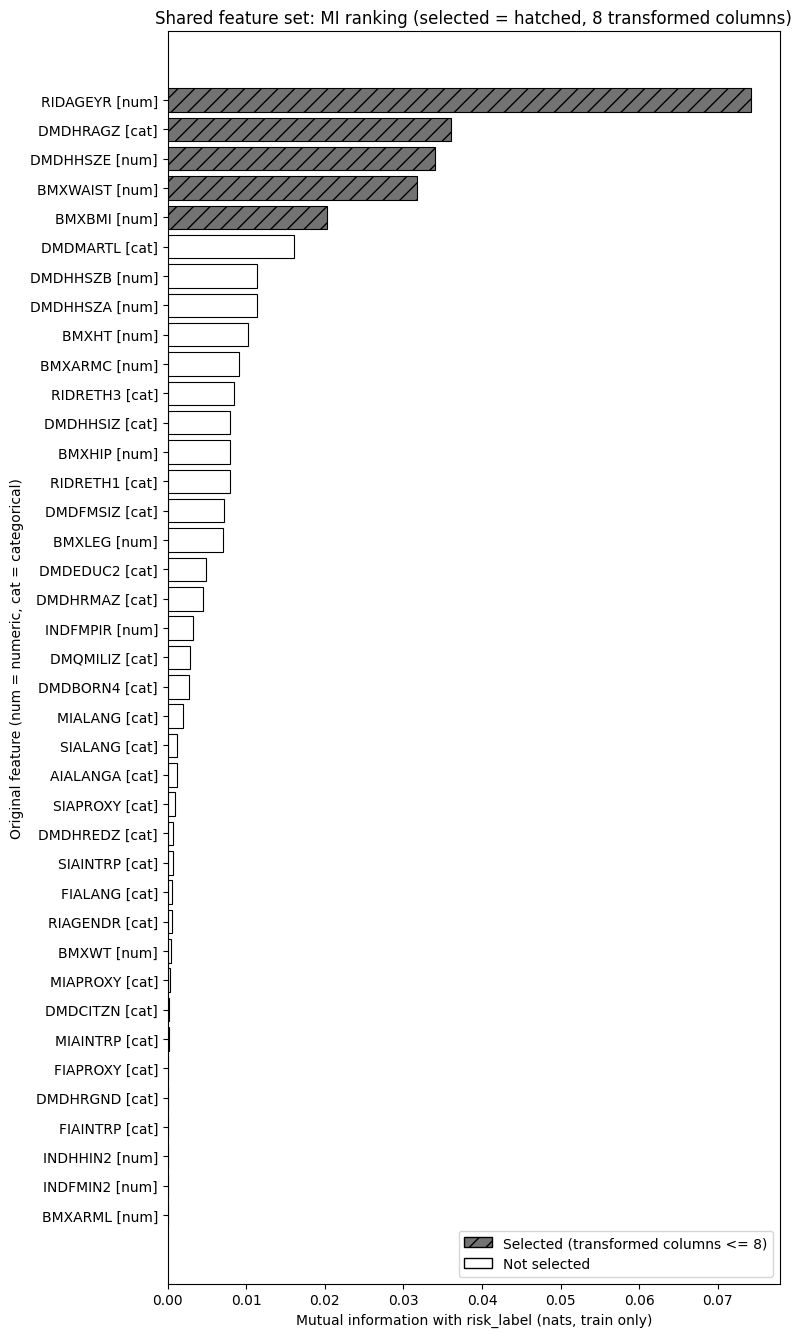

In [32]:
shared = {'selected_features': selected, 'numeric_features': sel_num, 'categorical_features': sel_cat,
          'transformed_dim': int(dim),
          'mi_ranking': [{'feature': f, 'mutual_info': mi[f], 'type': COL_TYPE[f]} for f in ranking],
          'split_hash': split_hash, 'seed': SEED,
          'dataset_version': DATASET_VERSION, 'created': pd.Timestamp.now(tz='UTC').isoformat()}
SHARED_PATH = RESULTS_DIR / 'shared_feature_set.json'
if SHARED_PATH.exists():
    old = json.loads(SHARED_PATH.read_text())
    same = old.get('selected_features') == selected and old.get('split_hash') == split_hash
    print('Existing shared feature set found ->', 'identical selection (deterministic)' if same else '[NOTICE] selection or split hash CHANGED; downstream notebooks must be re-run')
write_json_atomic(shared, SHARED_PATH)
chk = json.loads(SHARED_PATH.read_text())
assert chk['selected_features'] == selected and chk['transformed_dim'] <= MAX_DIM and chk['split_hash'] == split_hash
print('[VERIFIED] shared_feature_set.json saved:', SHARED_PATH)

from matplotlib.patches import Patch
rk = log_df.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, max(3.0, 0.32 * len(rk) + 1)))
for i, r in rk.iterrows():
    is_sel = r['decision'] == 'selected'
    ax.barh(i, r['mutual_info'], facecolor='0.45' if is_sel else 'white', edgecolor='black',
            hatch='//' if is_sel else '', linewidth=0.8)
ax.set_yticks(range(len(rk))); ax.set_yticklabels([f"{r['feature']} [{'cat' if r['type'] == 'categorical' else 'num'}]" for _, r in rk.iterrows()])
ax.set_xlabel('Mutual information with risk_label (nats, train only)'); ax.set_ylabel('Original feature (num = numeric, cat = categorical)')
ax.set_title(f'Shared feature set: MI ranking (selected = hatched, {dim} transformed columns)')
ax.legend(handles=[Patch(facecolor='0.45', edgecolor='black', hatch='//', label='Selected (transformed columns <= 8)'),
                   Patch(facecolor='white', edgecolor='black', label='Not selected')], loc='lower right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'shared_feature_mi_ranking.png', dpi=150); plt.show()

## Section 3 — Candidate models and hyper-parameter tuning (train only)
Three scikit-learn families, each as `Pipeline(preprocessor + classifier)` so imputing/scaling/encoding is **refit inside every CV fold** (no leakage). Class imbalance: `class_weight='balanced'` (LR, RF) and balanced sample weights (HistGradientBoosting). `GridSearchCV` with `StratifiedKFold(5, shuffle=True, random_state=42)`, `scoring='roc_auc'`, on **train rows only**. Test data is not touched in this section.

In [33]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
GRIDS = {
    'LogisticRegression': {'C': [0.01, 0.1, 1.0, 10.0]},
    'RandomForest': {'n_estimators': [200], 'max_depth': [4, 8, None], 'min_samples_leaf': [5, 10, 20]},
    'HistGradientBoosting': {'learning_rate': [0.05, 0.1], 'max_iter': [100, 200], 'max_leaf_nodes': [8, 15]},
}
def candidate_estimators():
    return {
        'LogisticRegression': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED),
        'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1),
        'HistGradientBoosting': HistGradientBoostingClassifier(early_stopping=False, random_state=SEED),
    }

def fit_params_for(pipe, y):
    # HistGradientBoosting: balanced sample weights (LR/RF use class_weight='balanced')
    if isinstance(pipe.named_steps['clf'], HistGradientBoostingClassifier):
        return {'clf__sample_weight': compute_sample_weight('balanced', y)}
    return {}

fmt = lambda v, nd=3: 'n/a' if v is None else f'{v:.{nd}f}'

def tune_candidates(feature_cols):
    # Tunes all candidates on TRAIN (CV) and scores them on VALIDATION. The TEST set is never used here.
    num = [c for c in feature_cols if c in NUMERIC_COLS]; cat = [c for c in feature_cols if c in CAT_COLS]
    Xtr, Xva = X_train[feature_cols], X_val[feature_cols]
    searches, p_val, rows, t_all = {}, {}, [], time.time()
    for name, clf in candidate_estimators().items():
        pipe = Pipeline([('prep', make_preprocessor(num, cat)), ('clf', clf)])
        gs = GridSearchCV(pipe, {f'clf__{k}': v for k, v in GRIDS[name].items()}, cv=CV, scoring='roc_auc',
                          n_jobs=1, refit=True, error_score='raise')
        t0 = time.time(); gs.fit(Xtr, y_train, **fit_params_for(pipe, y_train))
        assert list(gs.best_estimator_.classes_) == [0, 1]
        searches[name] = gs; p_val[name] = gs.predict_proba(Xva)[:, 1]
        thr, found = pick_threshold(y_val, p_val[name]); mv = compute_metrics(y_val, p_val[name], thr)
        rows.append({'model': name, 'best_params': {k.replace('clf__', ''): v for k, v in gs.best_params_.items()},
                     'cv_auc_train': float(gs.best_score_), 'val_auc': mv['roc_auc'], 'val_threshold': thr,
                     'val_sens_at_spec>=0.70': mv['sensitivity'], 'val_specificity': mv['specificity'],
                     'spec_constraint_met': found, 'tune_sec': round(time.time() - t0, 1)})
        print(f'  tuned {name:<22} best CV AUC={gs.best_score_:.4f}  ({time.time() - t0:.1f}s)  params={rows[-1]["best_params"]}')
    table = pd.DataFrame(rows)
    selected_name = max(table['model'], key=lambda n: round(float(table.loc[table.model == n, 'val_auc'].iloc[0]), 6))
    table['selected'] = table['model'] == selected_name
    return {'feature_cols': list(feature_cols), 'searches': searches, 'p_val': p_val, 'table': table,
            'selected': selected_name, 'tune_sec': round(time.time() - t_all, 1)}

def show_validation_table(sel):
    t = sel['table']
    out = pd.DataFrame({'model': t['model'], 'CV AUC (train)': t['cv_auc_train'].map(fmt),
                        'VAL ROC-AUC': t['val_auc'].map(fmt), 'val thr': t['val_threshold'].map(lambda v: fmt(v, 4)),
                        'VAL sens @ spec>=0.70': t['val_sens_at_spec>=0.70'].map(fmt),
                        'VAL spec': t['val_specificity'].map(fmt),
                        'best params': t['best_params'].map(lambda d: json.dumps(d, default=str)),
                        'selected': t['selected'].map(lambda b: '<-- selected' if b else '')})
    print(out.to_string(index=False))

print('Grids:', json.dumps(GRIDS))

Grids: {"LogisticRegression": {"C": [0.01, 0.1, 1.0, 10.0]}, "RandomForest": {"n_estimators": [200], "max_depth": [4, 8, null], "min_samples_leaf": [5, 10, 20]}, "HistGradientBoosting": {"learning_rate": [0.05, 0.1], "max_iter": [100, 200], "max_leaf_nodes": [8, 15]}}


In [34]:
# ---- Run results helpers (contract: results/<family>/run_<experiment>_seed<seed>.json) ----
def _iso_now(): return pd.Timestamp.now(tz='UTC').isoformat()

def _common_fields(experiment, family, t0):
    return {'runId': f'{family}_{experiment}_seed{SEED}', 'family': family, 'experiment': experiment, 'seed': SEED,
            'timestamp': _iso_now(), 'dataset_version': DATASET_VERSION, 'split_hash': split_hash,
            'positive_class': POSITIVE, 'versions': VERSIONS, 'backend': 'CPU'}

def _write_result(payload, results_dir, family, experiment, preds=None):
    # Never overwrite an existing COMPLETED result with a FAILED one.
    path = Path(results_dir) / family / f'run_{experiment}_seed{SEED}.json'
    if payload['status'] == 'failed' and path.exists():
        try: old = json.loads(path.read_text())
        except Exception: old = {}
        if old.get('status') == 'completed':
            print(f'[KEPT] existing completed result preserved: {path.name}'); return path, False
    if preds is not None:
        pp = Path(results_dir) / 'predictions' / f'{family}_{experiment}_seed{SEED}.csv'
        pp.parent.mkdir(parents=True, exist_ok=True)
        tmp = pp.with_suffix('.csv.tmp'); preds.to_csv(tmp, index=False); os.replace(tmp, pp)
    write_json_atomic(payload, path)
    return path, True

def _failed_payload(experiment, exc, t0, family='ml'):
    msg = f'{type(exc).__name__}: {" ".join(str(exc).split())[:300]}'     # readable, no stack trace
    return {**_common_fields(experiment, family, t0), 'model_name': None, 'status': 'failed', 'error': msg,
            'feature_set': None, 'n_transformed_features': None, 'config': {},
            'runtime_sec': round(time.time() - t0, 2), 'peak_memory_mb': round(peak_memory_mb(), 1)}

def record_failure(experiment, exc, t0=None, results_dir=None, family='ml'):
    payload = _failed_payload(experiment, exc, t0 or time.time(), family)
    _write_result(payload, results_dir or RESULTS_DIR, family, experiment)
    return payload

def safe_run(experiment, builder, results_dir=None, family='ml', t0=None):
    # builder() -> dict(model_name, feature_set, n_transformed_features, config, evaluation, predictions)
    results_dir = Path(results_dir or RESULTS_DIR); t0 = t0 or time.time()
    try:
        out = builder()
        payload = {**_common_fields(experiment, family, t0), 'model_name': out['model_name'], 'status': 'completed',
                   'error': None, 'feature_set': out['feature_set'], 'n_transformed_features': out['n_transformed_features'],
                   'config': out['config'], 'runtime_sec': round(time.time() - t0, 2),
                   'peak_memory_mb': round(peak_memory_mb(), 1), **out['evaluation']}
        preds = out['predictions']
    except Exception as e:
        payload, preds = _failed_payload(experiment, e, t0, family), None
        print(f'[FAILED] run {experiment}: {payload["error"]}')
    path, written = _write_result(payload, results_dir, family, experiment, preds)
    return payload

# ---- Adapter class ----
class MLAdapter:
    # fit(X, y) / predict_proba(X) -> positive-class probability / describe() -> dict
    def __init__(self, template, model_name, feature_cols):
        self.template, self.model_name, self.feature_cols, self.pipeline_ = template, model_name, list(feature_cols), None
    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        self.pipeline_ = clone(self.template)
        self.pipeline_.fit(X[self.feature_cols], y, **fit_params_for(self.pipeline_, y))
        assert list(self.pipeline_.classes_) == [0, 1]
        return self
    def predict_proba(self, X):
        return self.pipeline_.predict_proba(X[self.feature_cols])[:, 1]
    def n_transformed(self):
        return int(len(self.pipeline_.named_steps['prep'].get_feature_names_out()))
    def describe(self):
        clf = self.pipeline_.named_steps['clf']
        return {'family': 'ml', 'model_name': self.model_name, 'estimator': type(clf).__name__,
                'hyperparameters': clf.get_params(), 'input_features': self.feature_cols,
                'n_transformed_features': self.n_transformed(), 'positive_class': POSITIVE}

RUNS = {}   # in-memory handles to finished runs (adapter, probabilities)

def make_builder(sel, experiment, extra_config):
    feats = sel['feature_cols']
    def _builder():
        name = sel['selected']
        ad = MLAdapter(sel['searches'][name].best_estimator_, name, feats).fit(X_train, y_train)
        p_val = ad.predict_proba(X_val)
        assert np.allclose(p_val, sel['p_val'][name], atol=1e-9), 'refit differs from tuned model on validation'
        p_test = ad.predict_proba(X_test)                      # the ONLY test scoring: the selected model
        ev = evaluate_run(y_val, p_val, y_test, p_test)
        RUNS[experiment] = {'adapter': ad, 'p_val': p_val, 'p_test': p_test, 'selection': sel}
        cfg = {'selected_model': name, 'selection_rule': 'highest validation ROC-AUC',
               'best_params': sel['table'].set_index('model').loc[name, 'best_params'],
               'tuning': {'search': 'GridSearchCV', 'cv': 'StratifiedKFold(5, shuffle=True, random_state=42)',
                          'scoring': 'roc_auc', 'grids': GRIDS, 'tune_sec': sel['tune_sec']},
               'class_imbalance': 'class_weight=balanced (LR, RF); balanced sample weights (HistGradientBoosting)',
               'preprocessing': 'numeric: median impute + StandardScaler; categorical: most_frequent impute + OneHotEncoder(handle_unknown=ignore, drop=if_binary); fit on train only',
               'threshold_rule': 'max sensitivity on validation subject to specificity >= 0.70; applied once to test',
               'metrics_weighting': 'unweighted',
               'validation_table': sel['table'].drop(columns=['tune_sec']).to_dict('records'), **extra_config}
        return {'model_name': name, 'feature_set': feats, 'n_transformed_features': ad.n_transformed(), 'config': cfg,
                'evaluation': ev, 'predictions': pd.DataFrame({'row_pos': np.arange(len(y_test)), 'y_true': y_test, 'y_prob': p_test})}
    return _builder
print('[VERIFIED] run helpers, adapter and failure-safe runner defined')

[VERIFIED] run helpers, adapter and failure-safe runner defined


In [35]:
# ---- Tune the MAIN experiment (shared reduced feature set; train only) ----
T0_MAIN = time.time()
print(f'MAIN experiment: {len(MAIN_FEATURES)} features -> {dim} transformed columns')
try:
    main_sel = tune_candidates(MAIN_FEATURES)
except Exception as e:
    record_failure('main', e, T0_MAIN); raise
print(f'[VERIFIED] 3 candidates tuned with 5-fold CV on train only in {main_sel["tune_sec"]}s')

MAIN experiment: 5 features -> 8 transformed columns
  tuned LogisticRegression     best CV AUC=0.7444  (0.9s)  params={'C': 0.1}
  tuned RandomForest           best CV AUC=0.7438  (33.7s)  params={'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 200}
  tuned HistGradientBoosting   best CV AUC=0.7440  (9.4s)  params={'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 8}
[VERIFIED] 3 candidates tuned with 5-fold CV on train only in 44.0s


## Section 4 — Model selection on the VALIDATION set only
The final model is the candidate with the highest **validation ROC-AUC** (ties at 6 decimals go to the earlier-listed candidate). Validation metrics of all candidates are shown below; **no test metric is computed for any non-selected candidate**.

In [36]:
show_validation_table(main_sel)
print(f"\nSelected final model (validation ROC-AUC): {main_sel['selected']}")
assert main_sel['table']['selected'].sum() == 1
print('[VERIFIED] exactly one model selected using validation data only')

               model CV AUC (train) VAL ROC-AUC val thr VAL sens @ spec>=0.70 VAL spec                                                      best params     selected
  LogisticRegression          0.744       0.755  0.5400                 0.658    0.709                                                       {"C": 0.1}             
        RandomForest          0.744       0.751  0.5556                 0.709    0.702 {"max_depth": null, "min_samples_leaf": 20, "n_estimators": 200}             
HistGradientBoosting          0.744       0.762  0.5897                 0.688    0.711    {"learning_rate": 0.05, "max_iter": 100, "max_leaf_nodes": 8} <-- selected

Selected final model (validation ROC-AUC): HistGradientBoosting
[VERIFIED] exactly one model selected using validation data only


## Section 5 — One-time test evaluation of the selected model
The selected pipeline is refit on train (same hyper-parameters), its **decision threshold is chosen on validation** (max sensitivity with specificity ≥ 0.70) and applied **once** to the test set. Metrics at threshold 0.5 are reported separately. Saved as `results/ml/run_main_seed42.json` + private predictions CSV; the fitted pipeline goes to `results/ml/final_pipeline.joblib`. All metrics are unweighted.

In [37]:
main_run = safe_run('main', make_builder(main_sel, 'main', {'feature_set_type': 'shared reduced feature set (results/shared_feature_set.json)'}), t0=T0_MAIN)
assert main_run['status'] == 'completed', main_run['error']

th, t5 = main_run['metrics_at_threshold'], main_run['metrics_at_0.5']
print(f"Model: {main_run['model_name']} | backend {main_run['backend']} | runtime {main_run['runtime_sec']}s | peak mem {main_run['peak_memory_mb']} MB")
print(f"Threshold (chosen on VALIDATION): {main_run['threshold']:.4f}  (spec>=0.70 achievable on validation: {main_run['threshold_found']})")
print(f"TEST n={main_run['test_n']}, prevalence={main_run['test_prevalence']:.3f}\n")
rows = []
for k in ['sensitivity', 'specificity', 'precision', 'f1', 'accuracy', 'roc_auc']:
    ci = main_run['ci95'][k]
    rows.append({'metric': k, 'at val-chosen thr': fmt(th[k]), '95% bootstrap CI': 'n/a' if ci is None else f'[{ci[0]:.3f}, {ci[1]:.3f}]',
                 'at thr 0.5': fmt(t5[k])})
print(pd.DataFrame(rows).to_string(index=False))
print('Confusion [[TN, FP], [FN, TP]] at val-chosen thr:', th['confusion'], '| at 0.5:', t5['confusion'])

# save the fitted final pipeline (portable scikit-learn objects only)
FINAL_PIPE_PATH = ML_DIR / 'final_pipeline.joblib'
tmp = FINAL_PIPE_PATH.with_suffix('.joblib.tmp'); joblib.dump(RUNS['main']['adapter'].pipeline_, tmp); os.replace(tmp, FINAL_PIPE_PATH)
_re = joblib.load(FINAL_PIPE_PATH)
assert np.allclose(_re.predict_proba(X_test[MAIN_FEATURES])[:, 1], RUNS['main']['p_test'])
pred_file = PRED_DIR / 'ml_main_seed42.csv'
_pf = pd.read_csv(pred_file)
assert list(_pf.columns) == ['row_pos', 'y_true', 'y_prob'] and len(_pf) == len(y_test) and (_pf.y_true.to_numpy() == y_test).all()
assert (ML_DIR / 'run_main_seed42.json').exists()
print('[VERIFIED] run_main_seed42.json, predictions CSV and final_pipeline.joblib saved and re-loadable')

Model: HistGradientBoosting | backend CPU | runtime 46.52s | peak mem 326.6 MB
Threshold (chosen on VALIDATION): 0.5897  (spec>=0.70 achievable on validation: True)
TEST n=678, prevalence=0.347

     metric at val-chosen thr 95% bootstrap CI at thr 0.5
sensitivity             0.677   [0.620, 0.739]      0.791
specificity             0.729   [0.686, 0.769]      0.630
  precision             0.570   [0.511, 0.629]      0.531
         f1             0.619   [0.570, 0.668]      0.636
   accuracy             0.711   [0.678, 0.743]      0.686
    roc_auc             0.759   [0.725, 0.796]      0.759
Confusion [[TN, FP], [FN, TP]] at val-chosen thr: [[323, 120], [76, 159]] | at 0.5: [[279, 164], [49, 186]]
[VERIFIED] run_main_seed42.json, predictions CSV and final_pipeline.joblib saved and re-loadable


## Section 6 — Reproducibility test (TC-10)
Refit the selected pipeline 5 times with the same seed and require **identical** test probabilities in 5 of 5 refits (compared with the saved main run). This only checks determinism; no new metrics are produced.

In [38]:
ref = RUNS['main']['p_test']; template = RUNS['main']['adapter'].template; name = main_run['model_name']
identical, max_diff = 0, 0.0
for i in range(5):
    random.seed(SEED); np.random.seed(SEED)
    p = MLAdapter(template, name, MAIN_FEATURES).fit(X_train, y_train).predict_proba(X_test)
    identical += int(np.array_equal(p, ref)); max_diff = max(max_diff, float(np.max(np.abs(p - ref))))
    print(f'  refit {i + 1}: identical = {np.array_equal(p, ref)}')
repro = {'test_case': 'TC-10', 'model_name': name, 'n_repeats': 5, 'identical_runs': identical, 'passed': identical == 5,
         'max_abs_diff': max_diff, 'seed': SEED, 'split_hash': split_hash, 'timestamp': _iso_now()}
write_json_atomic(repro, ML_DIR / 'repro_check.json')
assert identical == 5, f'TC-10 failed: only {identical}/5 identical (max abs diff {max_diff})'
print(f'[PASSED] TC-10: {identical}/5 refits gave identical test probabilities; saved results/ml/repro_check.json')

  refit 1: identical = True
  refit 2: identical = True
  refit 3: identical = True
  refit 4: identical = True
  refit 5: identical = True
[PASSED] TC-10: 5/5 refits gave identical test probabilities; saved results/ml/repro_check.json


## Section 7 — SUPPLEMENTARY: full pruned-feature experiment (seed 42)
Same pipeline types, same grids and same selection procedure, but using **all pruned features** instead of the shared reduced set. Saved as `run_full_seed42.json`. **This is a supplementary result and is not used in the headline comparison.**

In [39]:
T0_FULL = time.time()
print(f'FULL (supplementary) experiment: {len(KEPT_COLS)} features')
try:
    full_sel = tune_candidates(KEPT_COLS)
except Exception as e:
    record_failure('full', e, T0_FULL); raise
show_validation_table(full_sel)
print(f"\nSelected (validation ROC-AUC): {full_sel['selected']}")

full_run = safe_run('full', make_builder(full_sel, 'full', {'supplementary': True,
        'label': 'SUPPLEMENTARY full pruned-feature run; not used in the headline comparison',
        'feature_set_type': 'all pruned features'}), t0=T0_FULL)
assert full_run['status'] == 'completed', full_run['error']
fth = full_run['metrics_at_threshold']
print(f"\n[SUPPLEMENTARY] {full_run['model_name']} | {full_run['n_transformed_features']} transformed columns | thr={full_run['threshold']:.4f}")
print(f"  TEST sensitivity={fmt(fth['sensitivity'])}  specificity={fmt(fth['specificity'])}  ROC-AUC={fmt(fth['roc_auc'])}  accuracy={fmt(fth['accuracy'])}")
assert (ML_DIR / 'run_full_seed42.json').exists() and (PRED_DIR / 'ml_full_seed42.csv').exists()
print('[VERIFIED] run_full_seed42.json saved (supplementary)')

FULL (supplementary) experiment: 39 features


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 6, 7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown

  tuned LogisticRegression     best CV AUC=0.7686  (3.6s)  params={'C': 0.1}


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 6, 7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown

  tuned RandomForest           best CV AUC=0.7542  (45.0s)  params={'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 200}


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 6, 7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown

  tuned HistGradientBoosting   best CV AUC=0.7625  (25.4s)  params={'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 8}
               model CV AUC (train) VAL ROC-AUC val thr VAL sens @ spec>=0.70 VAL spec                                                      best params     selected
  LogisticRegression          0.769       0.781  0.5506                 0.692    0.725                                                       {"C": 0.1}             
        RandomForest          0.754       0.774  0.5171                 0.684    0.711 {"max_depth": null, "min_samples_leaf": 10, "n_estimators": 200}             
HistGradientBoosting          0.763       0.783  0.5704                 0.718    0.709    {"learning_rate": 0.05, "max_iter": 100, "max_leaf_nodes": 8} <-- selected

Selected (validation ROC-AUC): HistGradientBoosting

[SUPPLEMENTARY] HistGradientBoosting | 89 transformed columns | thr=0.5704
  TEST sensitivity=0.698  specificity=0.713  ROC-AUC=0.771  accuracy=0.708
[VERIFI

## Section 8 — Plots (main run)
ROC curve, confusion matrix at the validation-chosen threshold, and feature importance. Plots use line styles, markers, hatching and printed numbers in addition to colour. Feature importance describes *model behaviour*, not causal effects.

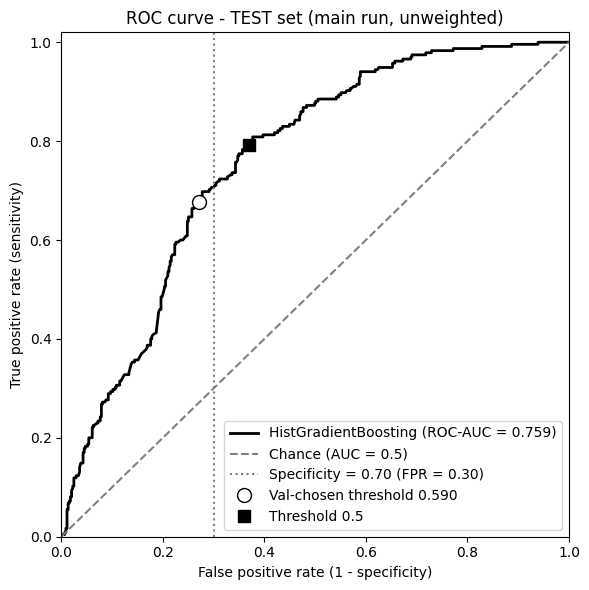

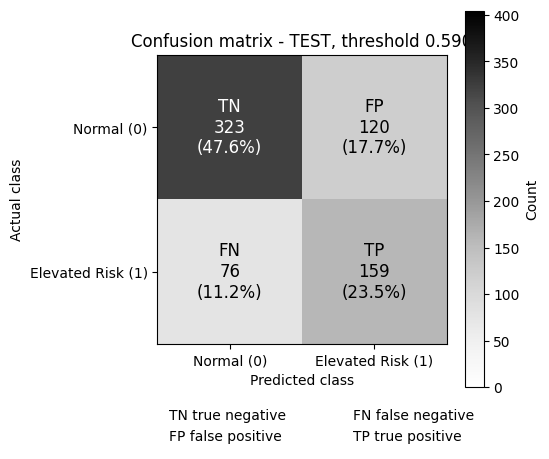

In [40]:
from matplotlib.lines import Line2D
y_t, p_t = y_test, RUNS['main']['p_test']
fpr, tpr, _ = roc_curve(y_t, p_t)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, linestyle='-', linewidth=2, color='black', label=f"{main_run['model_name']} (ROC-AUC = {fmt(th['roc_auc'])})")
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance (AUC = 0.5)')
ax.axvline(0.30, linestyle=':', color='gray', label='Specificity = 0.70 (FPR = 0.30)')
if th['sensitivity'] is not None and th['specificity'] is not None:
    ax.plot(1 - th['specificity'], th['sensitivity'], marker='o', markersize=10, markerfacecolor='white', markeredgecolor='black', linestyle='None',
            label=f"Val-chosen threshold {main_run['threshold']:.3f}")
if t5['sensitivity'] is not None and t5['specificity'] is not None:
    ax.plot(1 - t5['specificity'], t5['sensitivity'], marker='s', markersize=9, markerfacecolor='black', markeredgecolor='black', linestyle='None', label='Threshold 0.5')
ax.set_xlabel('False positive rate (1 - specificity)'); ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title('ROC curve - TEST set (main run, unweighted)'); ax.legend(loc='lower right'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / 'roc_main.png', dpi=150); plt.show()

cm = np.array(th['confusion']); tot = cm.sum()
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap='Greys', vmin=0, vmax=cm.max() * 1.25)
labels = [['TN', 'FP'], ['FN', 'TP']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{labels[i][j]}\n{cm[i, j]}\n({cm[i, j] / tot:.1%})', ha='center', va='center',
                color='white' if cm[i, j] > cm.max() * 0.6 else 'black', fontsize=12)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Normal (0)', 'Elevated Risk (1)']); ax.set_yticks([0, 1]); ax.set_yticklabels(['Normal (0)', 'Elevated Risk (1)'])
ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class'); ax.set_title(f"Confusion matrix - TEST, threshold {main_run['threshold']:.3f}")
cb = plt.colorbar(im, ax=ax); cb.set_label('Count')
ax.legend(handles=[Line2D([], [], linestyle='', label=t) for t in ['TN true negative', 'FP false positive', 'FN false negative', 'TP true positive']],
          loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'confusion_main.png', dpi=150); plt.show()

HistGradientBoostingClassifier has no native importance; see permutation importance below.


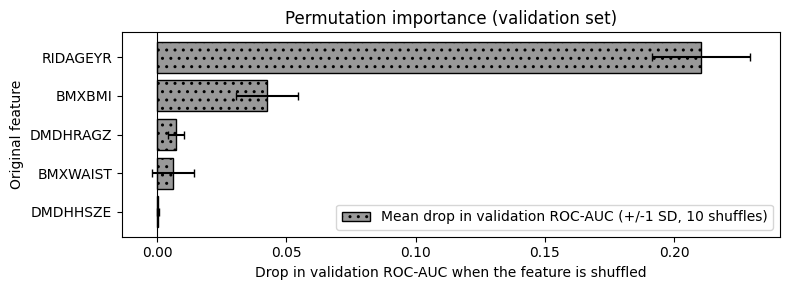

[VERIFIED] ROC, confusion matrix and importance plots created and saved under results/ml/figures


In [41]:
from sklearn.inspection import permutation_importance
pipe = RUNS['main']['adapter'].pipeline_; clf = pipe.named_steps['clf']; names = pipe.named_steps['prep'].get_feature_names_out()

# (a) model-native importance on transformed columns
if hasattr(clf, 'coef_'):
    vals = clf.coef_[0]; order_ = np.argsort(np.abs(vals))
    fig, ax = plt.subplots(figsize=(8, max(3, 0.4 * len(vals) + 1)))
    for k, idx in enumerate(order_):
        ax.barh(k, vals[idx], facecolor='0.35' if vals[idx] >= 0 else 'white', edgecolor='black', hatch='//' if vals[idx] >= 0 else '\\\\')
    ax.set_yticks(range(len(order_))); ax.set_yticklabels(names[order_]); ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Logistic-regression coefficient (standardised inputs; log-odds of Elevated Risk)'); ax.set_ylabel('Transformed feature')
    ax.set_title('Model coefficients (association, not causation)')
    ax.legend(handles=[Patch(facecolor='0.35', edgecolor='black', hatch='//', label='Positive: raises Elevated-Risk score'),
                       Patch(facecolor='white', edgecolor='black', hatch='\\\\', label='Negative: lowers Elevated-Risk score')], loc='lower right')
    plt.tight_layout(); plt.savefig(FIG_DIR / 'native_importance_main.png', dpi=150); plt.show()
elif hasattr(clf, 'feature_importances_'):
    vals = clf.feature_importances_; order_ = np.argsort(vals)
    fig, ax = plt.subplots(figsize=(8, max(3, 0.4 * len(vals) + 1)))
    ax.barh(range(len(order_)), vals[order_], facecolor='0.45', edgecolor='black', hatch='//', label='Impurity-based importance')
    ax.set_yticks(range(len(order_))); ax.set_yticklabels(names[order_])
    ax.set_xlabel('Mean decrease in impurity'); ax.set_ylabel('Transformed feature'); ax.set_title('Model feature importance'); ax.legend(loc='lower right')
    plt.tight_layout(); plt.savefig(FIG_DIR / 'native_importance_main.png', dpi=150); plt.show()
else:
    print(f'{type(clf).__name__} has no native importance; see permutation importance below.')

# (b) permutation importance on the VALIDATION set (original features; test data not used)
pi = permutation_importance(pipe, X_val[MAIN_FEATURES], y_val, scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=1)
o = np.argsort(pi.importances_mean)
fig, ax = plt.subplots(figsize=(8, max(3, 0.4 * len(o) + 1)))
ax.barh(range(len(o)), pi.importances_mean[o], xerr=pi.importances_std[o], facecolor='0.6', edgecolor='black', hatch='..', capsize=3,
        label='Mean drop in validation ROC-AUC (+/-1 SD, 10 shuffles)')
ax.set_yticks(range(len(o))); ax.set_yticklabels(np.array(MAIN_FEATURES)[o]); ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Drop in validation ROC-AUC when the feature is shuffled'); ax.set_ylabel('Original feature')
ax.set_title('Permutation importance (validation set)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'permutation_importance_main.png', dpi=150); plt.show()
print('[VERIFIED] ROC, confusion matrix and importance plots created and saved under results/ml/figures')

## Section 9 — Single-record prediction demo, failure-isolation test, summary
`predict_single_record` validates the input field by field **before** the model is called; invalid input returns an error list and the model is never invoked. Output is a research score, not a diagnosis.

In [42]:
import numbers
SINGLE_NUM_RANGE = {c: (float(X_train[c].min()), float(X_train[c].max())) for c in MAIN_FEATURES if c in NUMERIC_COLS}
SINGLE_CAT_LEVELS = {c: set(X_train[c].dropna().unique().tolist()) for c in MAIN_FEATURES if c in CAT_COLS}
MAIN_THRESHOLD = main_run['threshold']
_CALLS = {'n': 0}

def _score_record(df):
    _CALLS['n'] += 1
    return float(RUNS['main']['adapter'].predict_proba(df)[0])

def predict_single_record(feature_dict):
    # Required fields = shared feature set. Numeric: finite number inside the observed train range +/- 50% of its span.
    # Categorical: must be one of the category codes seen in train. Missing/None values are rejected.
    errors = []
    if not isinstance(feature_dict, dict):
        return {'valid': False, 'errors': [{'field': '<input>', 'error': 'input must be a dict of field -> value'}]}
    for k in feature_dict:
        if str(k).upper() in FORBIDDEN:
            errors.append({'field': k, 'error': 'field is not allowed as a predictor'})
    for c in MAIN_FEATURES:
        if c not in feature_dict or feature_dict[c] is None:
            errors.append({'field': c, 'error': 'required field is missing'}); continue
        v = feature_dict[c]
        if c in SINGLE_NUM_RANGE:
            if isinstance(v, bool) or not isinstance(v, numbers.Real) or not np.isfinite(v):
                errors.append({'field': c, 'error': f'must be a finite number, got {v!r}'}); continue
            lo, hi = SINGLE_NUM_RANGE[c]; span = hi - lo
            if not (lo - 0.5 * span <= v <= hi + 0.5 * span):
                errors.append({'field': c, 'error': f'{v} outside plausible range [{lo - 0.5 * span:.4g}, {hi + 0.5 * span:.4g}]'})
        else:
            try: ok = v in SINGLE_CAT_LEVELS[c]
            except TypeError: ok = False
            if not ok:
                errors.append({'field': c, 'error': f'{v!r} is not a known category; allowed: {sorted(SINGLE_CAT_LEVELS[c])}'})
    if errors:
        return {'valid': False, 'errors': errors}               # model NOT called
    score = _score_record(pd.DataFrame([{c: feature_dict[c] for c in MAIN_FEATURES}]))
    return {'model': main_run['model_name'], 'score': score,
            'label': POSITIVE if score >= MAIN_THRESHOLD else NEGATIVE, 'threshold': MAIN_THRESHOLD, 'warning': WARNING_TEXT}

complete = X_val[MAIN_FEATURES].notna().all(axis=1)
assert complete.any(), 'no complete validation row available for the demo'
valid_rec = X_val.loc[complete.idxmax(), MAIN_FEATURES].to_dict()
print('Valid example input:  ', valid_rec)
before = _CALLS['n']; res_ok = predict_single_record(valid_rec); print('Result:', res_ok)
assert _CALLS['n'] == before + 1 and set(res_ok) == {'model', 'score', 'label', 'threshold', 'warning'} and 0 <= res_ok['score'] <= 1

bad_rec = dict(valid_rec)
num_demo = next((c for c in MAIN_FEATURES if c in NUMERIC_COLS), None)
if num_demo: bad_rec[num_demo] = 'abc'
drop_demo = [c for c in MAIN_FEATURES if c != num_demo][:1] or [MAIN_FEATURES[0]]
bad_rec.pop(drop_demo[0], None)
print('\nInvalid example input:', bad_rec)
before = _CALLS['n']; res_bad = predict_single_record(bad_rec)
print('Result:', json.dumps(res_bad, indent=1, default=str))
assert res_bad['valid'] is False and len(res_bad['errors']) >= 1 and _CALLS['n'] == before
print('[PASSED] valid record scored; invalid record rejected with field-level errors and the model was NOT called')

Valid example input:   {'RIDAGEYR': 21.0, 'DMDHRAGZ': 4.0, 'DMDHHSZE': 1.0, 'BMXWAIST': 67.3, 'BMXBMI': 21.3}
Result: {'model': 'HistGradientBoosting', 'score': 0.05521562750968038, 'label': 'Normal', 'threshold': 0.5897166637035672, 'warning': 'Research/educational use only. Not a diagnosis or medical advice.'}

Invalid example input: {'RIDAGEYR': 'abc', 'DMDHHSZE': 1.0, 'BMXWAIST': 67.3, 'BMXBMI': 21.3}
Result: {
 "valid": false,
 "errors": [
  {
   "field": "RIDAGEYR",
   "error": "must be a finite number, got 'abc'"
  },
  {
   "field": "DMDHRAGZ",
   "error": "required field is missing"
  }
 ]
}
[PASSED] valid record scored; invalid record rejected with field-level errors and the model was NOT called


In [43]:
# ---- Failure-isolation test: an injected failure must not damage earlier completed results ----
def _sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
protected = sorted(ML_DIR.glob('run_*_seed42.json')) + [ML_DIR / 'repro_check.json', SHARED_PATH, PRED_DIR / 'ml_main_seed42.csv', PRED_DIR / 'ml_full_seed42.csv']
before_hash = {str(p): _sha(p) for p in protected}
assert all(json.loads(p.read_text()).get('status') == 'completed' for p in ML_DIR.glob('run_*_seed42.json'))

def _boom():
    raise RuntimeError('Injected failure for isolation test')

fail_out = safe_run('main', _boom)                       # same target file as the completed main run
assert fail_out['status'] == 'failed'
after_hash = {str(p): _sha(p) for p in protected}
assert before_hash == after_hash, 'a completed result file was modified by a failed run!'
assert json.loads((ML_DIR / 'run_main_seed42.json').read_text())['status'] == 'completed'

# a failed run with no earlier result IS recorded (in a scratch folder), with a readable message and no stack trace
tmp_dir = Path(tempfile.mkdtemp())
safe_run('main', _boom, results_dir=tmp_dir)
rec = json.loads((tmp_dir / 'ml' / 'run_main_seed42.json').read_text())
assert rec['status'] == 'failed' and 'Injected failure' in rec['error'] and 'Traceback' not in rec['error']
shutil.rmtree(tmp_dir)
print(f'[PASSED] failure isolation: {len(protected)} protected files unchanged; failed run recorded readably when no earlier result exists')

[FAILED] run main: RuntimeError: Injected failure for isolation test
[KEPT] existing completed result preserved: run_main_seed42.json
[FAILED] run main: RuntimeError: Injected failure for isolation test
[PASSED] failure isolation: 6 protected files unchanged; failed run recorded readably when no earlier result exists


In [44]:
# ---- Final summary (re-read from the saved files) ----
saved = json.loads((ML_DIR / 'run_main_seed42.json').read_text())
sfull = json.loads((ML_DIR / 'run_full_seed42.json').read_text())
def line(r):
    m, m5, ci = r['metrics_at_threshold'], r['metrics_at_0.5'], r['ci95']
    c = lambda k: 'n/a' if ci[k] is None else f'[{ci[k][0]:.3f}, {ci[k][1]:.3f}]'
    return (f"  model={r['model_name']}  features={len(r['feature_set'])} (transformed {r['n_transformed_features']})  threshold={r['threshold']:.4f}\n"
            f"  TEST @val-chosen thr: sensitivity={fmt(m['sensitivity'])} {c('sensitivity')}  specificity={fmt(m['specificity'])}  "
            f"ROC-AUC={fmt(m['roc_auc'])} {c('roc_auc')}  accuracy={fmt(m['accuracy'])}\n"
            f"  TEST @0.5:            sensitivity={fmt(m5['sensitivity'])}  specificity={fmt(m5['specificity'])}  accuracy={fmt(m5['accuracy'])}\n"
            f"  test n={r['test_n']}, prevalence={r['test_prevalence']:.3f}, runtime={r['runtime_sec']}s")
print('=' * 100); print('CLASSICAL ML (scikit-learn) - FINAL SUMMARY   [family: ml]'); print('=' * 100)
print('HEADLINE (main, shared reduced feature set):'); print(line(saved))
print('\nSUPPLEMENTARY (full pruned features, not part of the headline comparison):'); print(line(sfull))
print(f"\nReproducibility TC-10: {json.loads((ML_DIR / 'repro_check.json').read_text())['identical_runs']}/5 identical")
print('Files: results/shared_feature_set.json | results/ml/run_main_seed42.json | results/ml/run_full_seed42.json | results/ml/repro_check.json | results/ml/final_pipeline.joblib')
print('\nNotes: cross-sectional NHANES 2017-2018 classification, NOT prediction of future disease; metrics are UNWEIGHTED; the test set was used once per final model.')
print('No claim is made about which model family performs best; compare only after all families have been run on the same split/features.')
print(WARNING_TEXT)

CLASSICAL ML (scikit-learn) - FINAL SUMMARY   [family: ml]
HEADLINE (main, shared reduced feature set):
  model=HistGradientBoosting  features=5 (transformed 8)  threshold=0.5897
  TEST @val-chosen thr: sensitivity=0.677 [0.620, 0.739]  specificity=0.729  ROC-AUC=0.759 [0.725, 0.796]  accuracy=0.711
  TEST @0.5:            sensitivity=0.791  specificity=0.630  accuracy=0.686
  test n=678, prevalence=0.347, runtime=46.52s

SUPPLEMENTARY (full pruned features, not part of the headline comparison):
  model=HistGradientBoosting  features=39 (transformed 89)  threshold=0.5704
  TEST @val-chosen thr: sensitivity=0.698 [0.638, 0.757]  specificity=0.713  ROC-AUC=0.771 [0.736, 0.807]  accuracy=0.708
  TEST @0.5:            sensitivity=0.791  specificity=0.625  accuracy=0.683
  test n=678, prevalence=0.347, runtime=77.24s

Reproducibility TC-10: 5/5 identical
Files: results/shared_feature_set.json | results/ml/run_main_seed42.json | results/ml/run_full_seed42.json | results/ml/repro_check.json |

## Limitations
> ⚠️ **Research/educational use only. Not a diagnosis or medical advice.**

- **Cross-sectional data:** results describe classification within the NHANES 2017–2018 cycle. They are **not** prediction of future disease, and the "Elevated Risk" label is defined only by an HbA1c range (5.7 % to < 6.5 %).
- **Unweighted metrics:** survey weights and design variables were removed, so results do **not** represent the US population and standard errors ignore the complex survey design.
- **Limited predictors:** only demographics and body measurements are used; no laboratory, lifestyle, family-history or clinical information.
- **Reduced shared feature set (≤ 8 transformed columns)** was chosen by univariate mutual information on train only; it can miss interactions and may not be ideal for classical models. The supplementary full-feature run is a single seed-42 run and is not used for the headline comparison.
- **Single fixed split, single seed:** one stratified 70/15/15 split; the test set is finite, so confidence intervals (bootstrap, 1000 resamples, test rows only) are wide and any difference between model families may fall within noise. No claim of clinical or model-family superiority is made.
- **Threshold choice:** the operating point (max sensitivity with specificity ≥ 0.70) is fixed on the validation set and is not clinically validated; positive predictive value depends strongly on prevalence.
- **Fairness not assessed:** sex and race/ethnicity may be predictors; subgroup performance was not evaluated. Feature importances/coefficients describe model behaviour, not causes.
- **Missing data** are imputed with train medians/modes; categories unseen in train are encoded as all-zeros.
- Prediction CSVs under `results/predictions/` are private working files and must not be included in exported reports.